le but de ce notebook est de comprendre les variables à notre disposition. Précisément, nous analyserons les données transactionnelles d'une entreprise du secteur Food & Beverage située en Indonésie. 

L'objectif est de comprendre la structure et la qualité des données avant toute transformation :

- identifier les fichiers et les variables disponibles ;
- comprendre la granularité des observations ;
- vérifier les types de données ;
- identifier les valeurs manquantes et les doublons ;
- vérifier la période couverte ;
- comprendre les relations entre les tables ;
- identifier les premières limites du jeu de données.

Aucune modification des données brutes n'est réalisée dans ce notebook.

In [74]:
import pandas as pd
import numpy as np

In [75]:
transactions = pd.read_csv("../data/raw/Transactions.csv")
products = pd.read_csv("../data/raw/Products.csv")

In [76]:
print(transactions.shape)
print(products.shape)

(53820, 11)
(96, 6)


Les deux jeux de données présentent des structures et des granularités différentes.

- Transactions : chaque ligne correspond à un ticket de caisse et contient des informations sur la vente, notamment son montant, les articles achetés et l'établissement concerné.
- Products : chaque ligne correspond à une référence de produit et décrit ses caractéristiques, telles que son nom, sa variante, sa catégorie et son prix.

Cette différence de granularité devra être prise en compte pour déterminer si une jointure entre les deux tables est possible et pertinente.

In [77]:
print(transactions.columns.tolist())
print(products.columns.tolist())

['Outlet', 'Date', 'Time', 'NetSales', 'Tax', 'TotalAmount', 'ReceiptNumber', 'Items', 'TotalItem', 'PaymentMethod', 'UseLoyaltyCard']
['ProductId', 'ProductName', 'Variant', 'Category', 'Price', 'Description']


Nous allons examiner les variables des deux tables afin d'identifier une éventuelle clé de jointure.

L'objectif est de déterminer si les produits mentionnés dans les tickets de caisse peuvent être associés de manière fiable aux références du catalogue.

En l'absence d'identifiant produit commun, une correspondance fondée sur les noms et les variantes nécessiterait des vérifications supplémentaires.

In [78]:
display(transactions.head())
display(products.head())

,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard
0,SHOP001,2025-01-02,07:01:05,20720.721,2279.279,23000,SHOP001JAN2500001,Basic Latte (Ice Arabica),1,BCA,0
1,SHOP001,2025-01-02,07:04:11,18018.018,1981.982,20000,SHOP001JAN2500002,BLACK (Houseblend),1,BCA,0
2,SHOP002,2025-01-02,07:10:46,39639.640,4360.360,44000,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",2,Cash,0
3,SHOP002,2025-01-02,07:14:25,36036.036,3963.964,40000,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",2,Cash,0
4,SHOP002,2025-01-02,07:23:05,36036.036,3963.964,40000,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",2,Cash,0


,ProductId,ProductName,Variant,Category,Price,Description
0,1,Add on Aren,-,Add on,0,"Tambahan sirup gula aren murni, memberikan ras..."
1,2,Add on Simple Syrup,-,Add on,0,Tambahan sirup gula sederhana (air dan gula) s...
2,3,Air Mineral,-,Other,5000,Air minum murni dalam kemasan
3,4,Americano,Hot Houseblend,Coffee,20000,Minuman kopi hitam yang dibuat dengan menambah...
4,5,Americano,Ice Houesblend,Coffee,20000,Minuman kopi hitam yang dibuat dengan menambah...


La colonne 'Items' de la table Transactions et les colonnes 'ProductName' et 'Variant' de la table Products semblent contenir des informations liées aux articles vendus.

Cependant, leurs structures diffèrent : 'Items' peut contenir plusieurs articles dans une même cellule, tandis que le catalogue décrit individuellement les références de produits.

Une correspondance directe entre ces colonnes ne peut donc pas être supposée sans vérification.

In [79]:
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 53820 entries, 0 to 53819
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Outlet          53820 non-null  str    
 1   Date            53820 non-null  str    
 2   Time            53820 non-null  str    
 3   NetSales        53820 non-null  float64
 4   Tax             53820 non-null  float64
 5   TotalAmount     53820 non-null  int64  
 6   ReceiptNumber   53820 non-null  str    
 7   Items           53820 non-null  str    
 8   TotalItem       53820 non-null  int64  
 9   PaymentMethod   53820 non-null  str    
 10  UseLoyaltyCard  53820 non-null  int64  
dtypes: float64(2), int64(3), str(6)
memory usage: 4.5 MB


In [80]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ProductId    96 non-null     int64
 1   ProductName  96 non-null     str  
 2   Variant      96 non-null     str  
 3   Category     96 non-null     str  
 4   Price        96 non-null     int64
 5   Description  96 non-null     str  
dtypes: int64(2), str(4)
memory usage: 4.6 KB


In [81]:
transactions.describe()

,NetSales,Tax,TotalAmount,TotalItem,UseLoyaltyCard
count,53820.000000,53820.000000,53820.000000,53820.000000,53820.000000
mean,22016.598672,2421.825705,24438.424378,1.151486,0.032200
std,10172.062610,1118.926902,11290.989512,0.358526,0.176532
min,0.000000,0.000000,0.000000,1.000000,0.000000
25%,18018.018000,1981.982000,20000.000000,1.000000,0.000000
50%,20720.721000,2279.279000,23000.000000,1.000000,0.000000
75%,27027.027000,2972.973000,30000.000000,1.000000,0.000000
max,54054.054000,5945.946000,60000.000000,2.000000,1.000000


Nous avons des minimums d'une valeur nulle pour les variables TotalAmount, Tax, Netscales. Il nous faut comprendre pourquoi nous avons ces valeurs minimales

In [82]:

transactions[transactions["TotalAmount"] == 0]

,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard
31,SHOP001,2025-01-02,10:37:45,0.0,0.0,0,SHOP001JAN2500013,Cappuccino (Hot Houseblend),1,Cash,1
37,SHOP002,2025-01-02,10:59:44,0.0,0.0,0,SHOP002JAN2500016,Friendly Coffee (Gedhe),1,Cash,1
78,SHOP001,2025-01-02,13:58:16,0.0,0.0,0,SHOP001JAN2500038,Cappuccino (Ice Houseblend),1,Cash,1
85,SHOP002,2025-01-02,14:35:33,0.0,0.0,0,SHOP002JAN2500025,Not Tiramisu Latte (Gedhe),1,Cash,1
86,SHOP003,2025-01-02,14:38:03,0.0,0.0,0,SHOP003JAN2500019,Waffle,1,Cash,1
...,...,...,...,...,...,...,...,...,...,...,...
53733,SHOP002,2025-09-30,15:49:25,0.0,0.0,0,SHOP002SEP2501046,Matcha Latte (Ice),1,Cash,1
53740,SHOP001,2025-09-30,16:30:01,0.0,0.0,0,SHOP001SEP2502665,Friendly Coffee (Ice),1,Cash,1
53745,SHOP002,2025-09-30,17:13:08,0.0,0.0,0,SHOP002SEP2501048,Thai Tea (Gedhe),1,Cash,1
53750,SHOP002,2025-09-30,17:41:50,0.0,0.0,0,SHOP002SEP2501049,Red Liquid,1,Cash,1


In [83]:
transactions.loc[transactions["TotalAmount"] == 0,"PaymentMethod"].value_counts()

PaymentMethod
Cash    1733
Name: count, dtype: int64

In [84]:
pd.crosstab(transactions["PaymentMethod"],transactions["TotalAmount"] == 0)

TotalAmount,False,True
PaymentMethod,,
BCA,42805,0
Cash,9180,1733
GoFood,102,0


In [85]:
(transactions["TotalAmount"] == 0).sum()

np.int64(1733)

In [86]:
pd.crosstab(transactions["UseLoyaltyCard"],transactions["TotalAmount"] == 0)

TotalAmount,False,True
UseLoyaltyCard,,
0,52087,0
1,0,1733


In [87]:
pd.crosstab(transactions["UseLoyaltyCard"],transactions["PaymentMethod"] == "Cash")

PaymentMethod,False,True
UseLoyaltyCard,,
0,42907,9180
1,0,1733


les différents croissements de tableau nous permettent de constater que 1733 transactions ont TotalAmount, Netsales et Tax nuls. Nous voyons également que pour des TotalAmount nuls, les transactions sont enregistrées en moyen de paiement Cash et utilisant les UseLoyaltyCard. Il existe donc une correspondance parfaite dans le jeu de données entre l'utilisation de la carte de fidélité et les transactions à montant nul. 
Pour la compréhension métier, ca soulève l'hypothése du produit gratuit(offert) à l'utilisation de la carte de fidélité. mais n'ayant pas suffisament d'informations sur le mécanisme exact, nous allons laisser ces données et cette hypothése telles qu'elles sont. 

In [88]:
difference = transactions['NetSales'] + transactions['Tax'] - transactions['TotalAmount']
difference.abs().describe()

count    53820.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
dtype: float64

la vérification éffectuée sur Total amount montre qu'il est bien la somme de Tax et NetSales. Il y'a aucun écart observé. 

In [89]:
# Vérification de l'unicité des tickets
print(transactions['ReceiptNumber'].value_counts().max())

1


le chiffre 1 correspond au nombre maximum de d'apparitions d'un reçu. Donc chaque reçu est unique.

In [90]:
#vérification de la période couverte par le dataset
pd.to_datetime(transactions['Date']).agg(['min', 'max'])

min   2025-01-02
max   2025-09-30
Name: Date, dtype: datetime64[us]

Nous constatons que le dataset va du début de mois Janvier jusqu'en fin septembre. Donc 09 mois

Les vérifications réalisées n'ont pas révélé de doublons d'identifiants de transactions ni d'incohérences dans la relation entre les montants nets, les taxes et les montants totaux.

Certaines particularités ont néanmoins été identifiées, notamment les transactions à montant nul et l'absence de clé de jointure directe entre les transactions et le catalogue des produits.

Notre étude cherchera à répondre à la problématique suivante :

"Pourquoi certaines journées présentent-elles un chiffre d'affaires plus élevé que d'autres, et quels facteurs sont associés à ces écarts ?"

L'analyse portera sur les performances quotidiennes des trois établissements, les variations du nombre de transactions, le panier moyen, les effets calendaires et la composition des tickets.

Les résultats serviront à identifier des pistes d'amélioration opérationnelle, dans les limites des informations disponibles.


In [91]:
print(products['ProductId'].value_counts().max())

1


chaque produit a un identifiant unique

In [92]:
products['Price'].describe()

count       96.000000
mean     21468.750000
std       7024.697971
min          0.000000
25%      20000.000000
50%      23000.000000
75%      25000.000000
max      30000.000000
Name: Price, dtype: float64

les observations ont été faites sur 96 produits avec des prix allant de 0 à 30000, pour un prix médian de 23000. Nous allons observer la raison des valeurs nulles

In [93]:
products[products['Price']==0]

,ProductId,ProductName,Variant,Category,Price,Description
0,1,Add on Aren,-,Add on,0,"Tambahan sirup gula aren murni, memberikan ras..."
1,2,Add on Simple Syrup,-,Add on,0,Tambahan sirup gula sederhana (air dan gula) s...


les 2 valeurs de prix nulles sont observées pour la catégorie 'Add On'. Il peut s'agir 

In [94]:
products['Category'].value_counts()

Category
Coffee        34
Menu Gedhe    19
Other         15
Tea           13
Snacks         9
Add on         6
Name: count, dtype: int64

In [95]:
products['Variant'].value_counts()

Variant
-                  56
Ice                 7
Hot                 7
Hot Houseblend      3
Hot Arabica         3
Ice Arabica         3
Houseblend          3
Arabica             3
Ice Houseblend      2
On The Rock         2
Basic Espresso      2
Ice Houesblend      1
Chocolate           1
Original            1
Hot double shot     1
Ice double shot     1
Name: count, dtype: int64

In [96]:
products['ProductName'].value_counts().head(10)

ProductName
Americano           4
Basic Latte         4
Cappuccino          4
Friendly Coffee     4
BLACK               3
WHITE               3
Banana Bread        2
Black Rice          2
Chocolate           2
Espresso Arabica    2
Name: count, dtype: int64

In [97]:
products[['ProductName', 'Variant']].duplicated().sum()

np.int64(0)




Objectif : comparer la contribution des trois établissements au chiffre d'affaires net total sur la période étudiée.

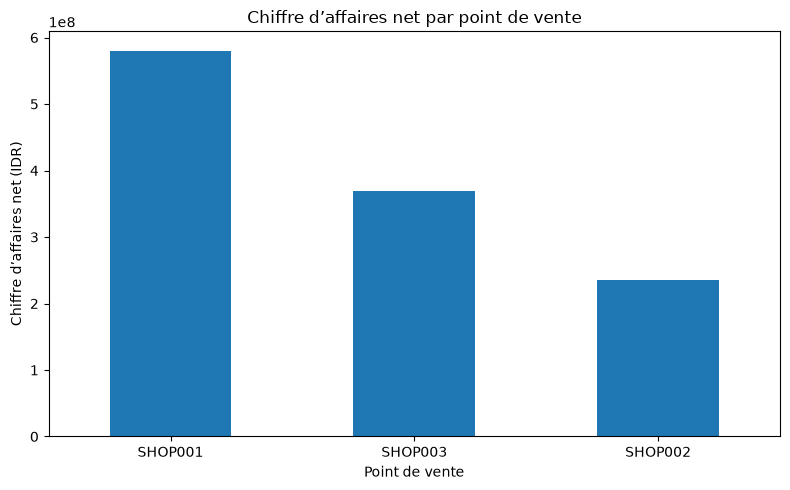

In [98]:
import matplotlib.pyplot as plt

ca_outlet = transactions.groupby('Outlet')['NetSales'].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
ca_outlet.plot(kind='bar')
plt.title('Chiffre d’affaires net par point de vente')
plt.xlabel('Point de vente')
plt.ylabel('Chiffre d’affaires net (IDR)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

le graphe nous montre que le SHOP001 a le CA le plus élevé, suivi du SHOP003 et SHOOP002. les facteurs expliquant cela reste à déterminer. 

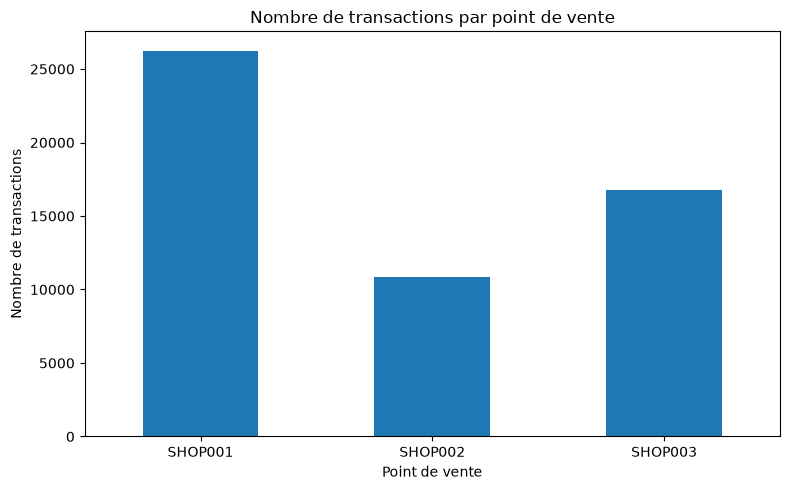

In [99]:
tickets_outlet = transactions.groupby('Outlet')['ReceiptNumber'].nunique()

tickets_outlet.plot(kind='bar', figsize=(8, 5))
plt.title('Nombre de transactions par point de vente')
plt.xlabel('Point de vente')
plt.ylabel('Nombre de transactions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [100]:
items = transactions['Items'].str.split(', ').explode()
top_products = items.value_counts().head(10)

top_products
print('Articles extraits :', len(items))
print('Articles déclarés :', transactions['TotalItem'].sum())

Articles extraits : 61973
Articles déclarés : 61973


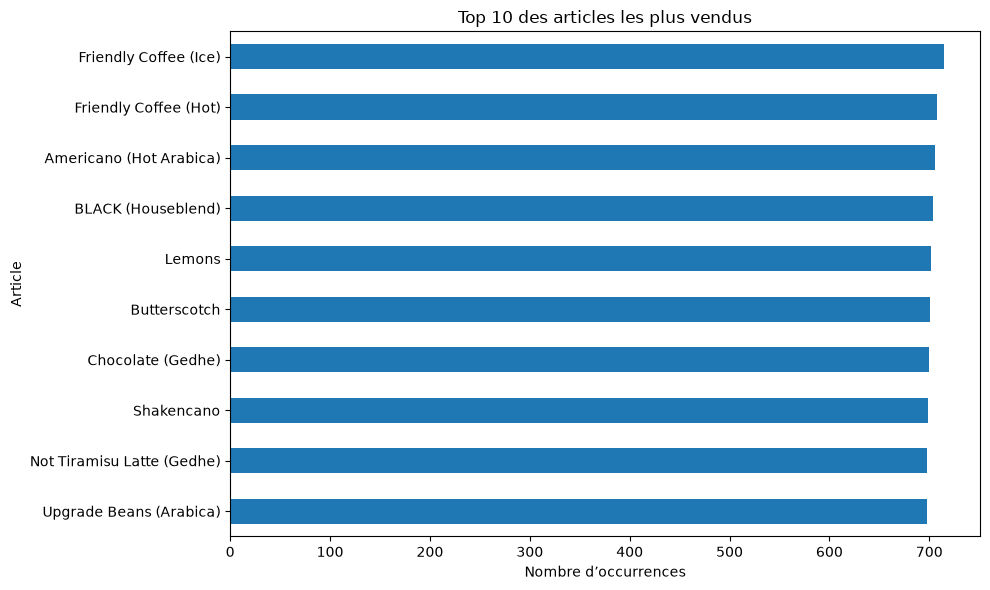

In [101]:
plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind='barh')
plt.title('Top 10 des articles les plus vendus')
plt.xlabel('Nombre d’occurrences')
plt.ylabel('Article')
plt.tight_layout()
plt.show()

Les dix articles les plus fréquents présentent des volumes d'occurrences relativement similaires. Cependant, cette analyse regroupe les trois points de vente et ne permet pas d'identifier les préférences propres à chaque établissement. Par ailleurs, la fréquence d'apparition d'un article ne permet pas, à elle seule, de déterminer sa contribution au chiffre d'affaires.

In [102]:
# Comparaison des 10 meilleurs produits vendus par boutiques sur la période étudiée.

sales_items = transactions[['Outlet', 'Items']].copy()
sales_items['Items'] = sales_items['Items'].str.split(', ')
sales_items = sales_items.explode('Items')


In [103]:
#Reinitialisation des index de produits vendus "sales_items"

sales_items = sales_items.reset_index(drop=True)

In [104]:
comparison = sales_items[sales_items['Items'].isin(top_products.index)]
comparison = pd.crosstab(comparison['Items'], comparison['Outlet'])
comparison

Outlet,SHOP001,SHOP002,SHOP003
Items,,,
Americano (Hot Arabica),340,153,213
BLACK (Houseblend),354,136,214
Butterscotch,335,134,232
Chocolate (Gedhe),312,161,227
Friendly Coffee (Hot),338,145,225
Friendly Coffee (Ice),343,145,227
Lemons,344,136,222
Not Tiramisu Latte (Gedhe),349,133,216
Shakencano,330,156,213


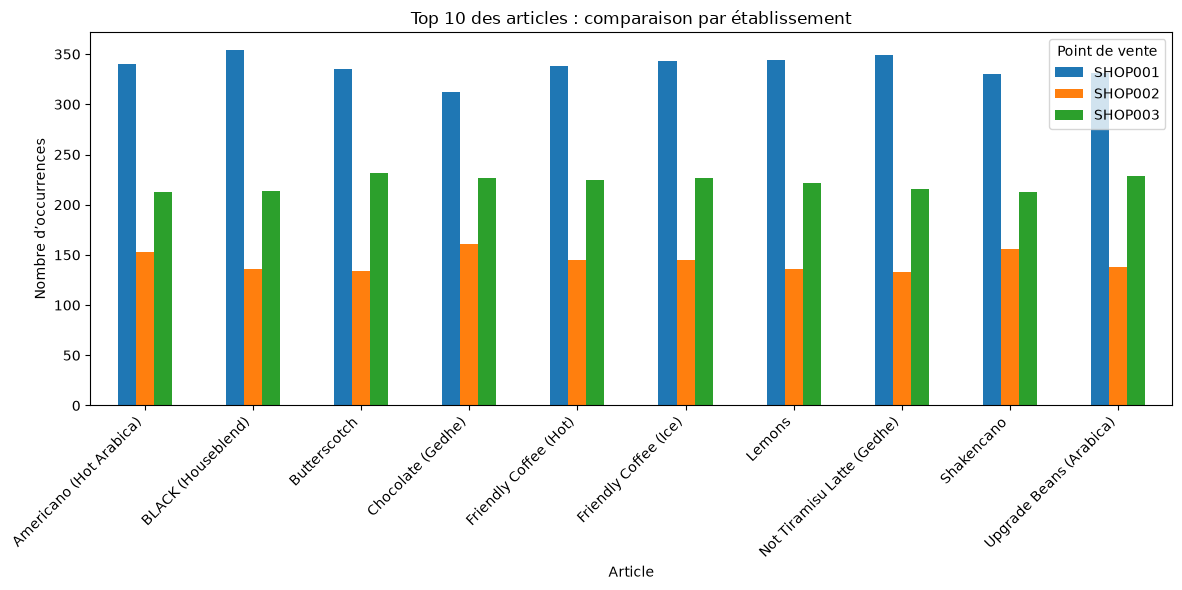

In [105]:
comparison.plot(kind='bar', figsize=(12, 6))
plt.title('Top 10 des articles : comparaison par établissement')
plt.xlabel('Article')
plt.ylabel('Nombre d’occurrences')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Point de vente')
plt.tight_layout()
plt.show()

Les dix articles les plus fréquents présentent des volumes de ventes plus élevés dans le SHOP001, suivi du SHOP003 puis du SHOP002. Pour ces articles, les occurrences enregistrées dans le SHOP001 sont approximativement deux fois supérieures à celles du SHOP002.

Cette répartition suit le même classement que celui observé pour le chiffre d'affaires net cumulé. Cependant, ces écarts peuvent s'expliquer par des différences de volume d'activité entre les établissements. Une comparaison des fréquences relatives sera nécessaire pour déterminer si les préférences d'achat diffèrent réellement d'un point de vente à l'autre.

Observations de l'évolution du CA quotidiennement

<Figure size 1200x500 with 0 Axes>

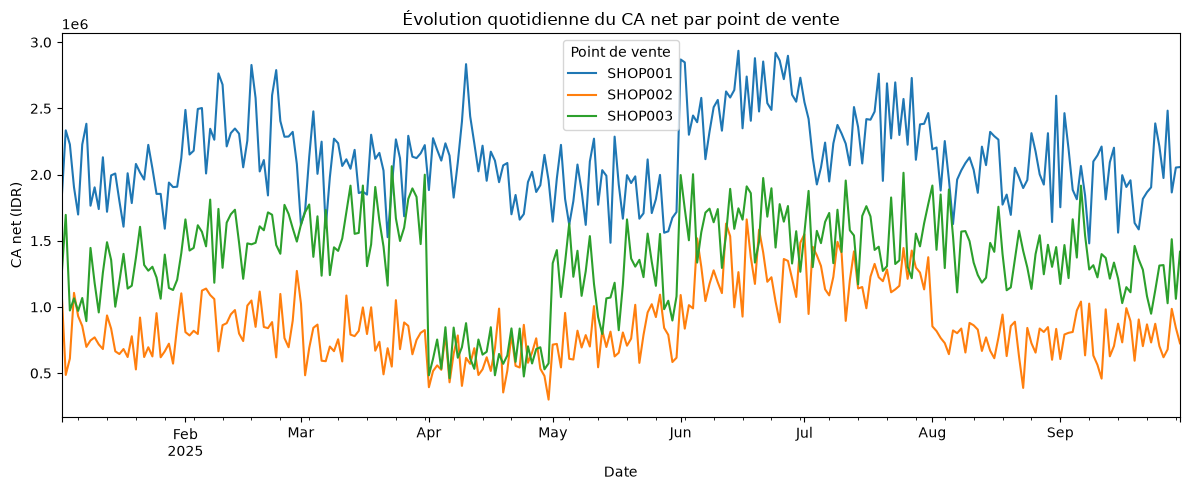

In [106]:
# définition des ventes quotidiennes
daily_sales = transactions.copy()
daily_sales['Date'] = pd.to_datetime(daily_sales['Date'])
daily_sales = daily_sales.groupby(['Date', 'Outlet'])['NetSales'].sum().unstack()

plt.figure(figsize=(12, 5))
daily_sales.plot(figsize=(12, 5))
plt.title('Évolution quotidienne du CA net par point de vente')
plt.xlabel('Date')
plt.ylabel('CA net (IDR)')
plt.legend(title='Point de vente')
plt.tight_layout()
plt.show()

L'évolution du chiffre d'affaires net quotidien présente des fluctuations importantes au sein des trois points de vente. Plusieurs périodes peuvent être distinguées.

- Janvier à mars : les établissements présentent des variations quotidiennes importantes, avec des niveaux de chiffre d'affaires différents.
- Avril à mai : une baisse particulièrement marquée est observée pour SHOP003, suivie d'une reprise progressive. La courbe de SHOP001 présente également une interruption qui nécessite une vérification.
- Juin à juillet : les trois établissements enregistrent des niveaux de chiffre d'affaires relativement élevés, particulièrement SHOP001 et SHOP002.
- Août à septembre : les chiffres d'affaires semblent revenir à des niveaux plus proches de ceux observés au début de la période.

Ces observations soulèvent plusieurs hypothèses concernant les variations de performance : évolution du nombre de transactions, modification du panier moyen, différences d'activité selon les périodes ou éventuelles interruptions d'exploitation.

Ces hypothèses devront être examinées lors de l'analyse approfondie des performances quotidiennes.

In [107]:
april_sales = daily_sales.loc['2025-04-01':'2025-04-30']
april_sales.count()

Outlet
SHOP001    30
SHOP002    30
SHOP003    30
dtype: int64

In [108]:
april_sales.isna().sum()

Outlet
SHOP001    0
SHOP002    0
SHOP003    0
dtype: int64

In [109]:
april_sales[april_sales.isna().any(axis=1)]

Outlet,SHOP001,SHOP002,SHOP003
Date,,,



L'analyse de la couverture temporelle montre que les trois établissements disposent de données de chiffre d'affaires pour l'ensemble des 30 jours d'avril 2025.

Aucune valeur manquante n'a été identifiée sur cette période.

La baisse importante du chiffre d'affaires de SHOP003 observée en avril ne peut donc pas être attribuée à l'absence de journées enregistrées dans le dataset.

Cette observation nécessitera une analyse complémentaire du volume de transactions et du panier moyen afin d'identifier les facteurs associés à cette baisse.